# Лабораторная 6. Остаточные свёрточные сети. Дроп-аут. Батч-нормализация

**Задание.**

*1. Архитектура.* Реализовать свёрточную сеть с блоками слоёв с соединениями
напрямую (остаточными блоками). Использовать свёрточные блоки различной
архитектуры: 1) свёрточные блоки из предыдущего задания; 2) свёрточные блоки с
соединениями напрямую; 3) bottleneck-блоки (свёртки $1 \times 1$); и слои:
1) пакетной нормализации (batchnorm), 2) дроп-аута (dropout).

*2. Выборки.* Использовать выборку CIFAR-10 или др. (MNIST, FashionMNIST - для
сравнения). Для выбранного датасета подобрать параметры, при которых для
построенной архитектуры достигается наивысшее качество классификации. Сравнить с
результатами свёрточной сети (не остаточной) на тех же выборках.

*3. Гиперпараметры:* количество эпох; коэффициент обучения; количество скрытых
слоёв (количество остаточных блоков); количество каналов; параметры kernel,
stride, padding преобразований Conv2d и MaxPool2d; количество скрытых слоёв и
нейронов в многослойном перцептроне на выходе сети.

## 1. Теория

### Данные

Основная выборка CIFAR-10: цветные изображения $32 \times 32$, три канала (красный,
зелёный, синий), 10 классов (самолёт, автомобиль, птица, кошка, олень, собака,
лягушка, лошадь, корабль, грузовик), 50000 обучающих и 10000 тестовых. MNIST и
FashionMNIST ($28 \times 28$, один канал) используются для сравнения.

Для перебора гиперпараметров из обучающей части CIFAR-10 берутся 5000
изображений для обучения и 2000 отложенных для оценки. Число эпох подбирается на
модели, обученной на 15000 изображениях. Тестовая выборка из 10000 изображений в
переборе не участвует. Яркости делятся на 255 и нормируются средним и стандартным
отклонением каждого канала по обучающей части.

### Остаточный блок

Блок учит не искомое преобразование $H(x)$ целиком, а поправку к
тождественному:

$$y = F(x) + x, \qquad F(x) = H(x) - x .$$

При обратном распространении производная слагаемого $x$ равна единице, поэтому
градиент проходит через блок без затухания:

$$\frac{\partial y}{\partial x} = \frac{\partial F}{\partial x} + I .$$

### Bottleneck-блок

Свёртки $1\times1$, $k\times k$ и $1\times1$ подряд: первая сжимает число каналов
вчетверо, свёртка $k\times k$ выполняется в узком пространстве, последняя
расширяет каналы обратно. Свёртка $1\times1$ смешивает только каналы и не смотрит
на соседей по пространству.

### Виды блоков и сетей

- plain: блок б) из лабораторной 5 без пуллинга и с батч-нормализацией,
  Conv-BN-ReLU-Conv-BN, затем ReLU, без соединения напрямую;
- residual: тот же блок с соединением напрямую, $y = \mathrm{ReLU}(F(x) + x)$;
- bottleneck: свёртки $1\times1$, $k\times k$, $1\times1$ с соединением напрямую.

В блоках шаг 1 и дополнение $\lfloor k/2 \rfloor$, поэтому размер карты признаков
не меняется и $F(x)$ можно сложить с $x$. Сеть: входной слой (свёртка и
уменьшение карты вдвое), первая стадия из блоков при $C$ каналах, переход с
удвоением каналов и уменьшением карты вдвое, вторая стадия из блоков при $2C$
каналах, усреднение по карте признаков и многослойный перцептрон на выходе. Для
CIFAR-10 размер карты $32 \to 16 \to 8$, для MNIST $28 \to 14 \to 7$.

Для сравнения берётся и сеть из лабораторной 5 с лучшими найденными там
параметрами: два блока а) Conv-ReLU-MaxPool, ядро свёртки 5, пуллинг с окном 3 и
шагом 2, SGD с коэффициентом обучения 0.01.

### Размер выхода свёртки и пуллинга

Для входа $n \times n$, ядра $k$, шага $s$ и дополнения $p$

$$n_{\text{out}} = \left\lfloor \frac{n + 2p - k}{s} \right\rfloor + 1 .$$

Уменьшение карты вдвое во входном слое и в переходе делается одним из способов
(kernel/stride/padding):

| Вариант | Conv2d | MaxPool2d |
|---|---|---|
| 1 | 3/1/1 | 2/2/0 |
| 2 | 3/1/1 | 3/2/1 |
| 3 | 3/2/1 | нет |
| 4 | 5/1/2 | 2/2/0 |

Во всех вариантах $32 \to 16$ и $28 \to 14$.

### Батч-нормализация

Каждый канал нормируется по мини-батчу:

$$\hat z = \frac{z - \mu_B}{\sqrt{\sigma_B^2 + \varepsilon}}, \qquad
  y = \gamma\hat z + \beta,$$

где $\mu_B$ и $\sigma_B^2$ считаются по батчу, а $\gamma$, $\beta$ обучаются. На
инференсе вместо статистик батча используются накопленные скользящие средние.

### Дроп-аут

При обучении обнуляется случайная доля $p$ активаций с масштабированием
оставшихся, на инференсе пропускается всё. `Dropout2d` выключает канал целиком.

### Что перебирается

| Гиперпараметр | Значения |
|---|---|
| тип блока | plain, residual, bottleneck |
| число блоков | 2, 4, 8 |
| батч-нормализация | есть, нет |
| дроп-аут | $0$, $0.2$, $0.5$ |
| число каналов $C$ | 16, 32 |
| коэффициент обучения | $0.01$, $0.05$, $0.1$ |
| Conv2d и MaxPool2d входного слоя и перехода | варианты 1-4 |
| размер ядра в блоках | 3, 5 |
| выходной перцептрон | без скрытых слоёв, $(64)$, $(128)$, $(128, 64)$ |
| число эпох | от 1 до 20 |

Перебор последовательный: на каждом этапе фиксируются лучшие значения
предыдущих. Настраивается остаточная сеть, поэтому тип блока выбирается из
residual и bottleneck, а plain участвует в переборе для сравнения. На этапах
перебора каждая конфигурация обучается 10 эпох, SGD с моментом 0.9, батчи по 64. В
таблицах обе точности взяты на эпохе с наибольшей accuracy на отложенной
выборке, точность на обучающей считается по 1000 её изображений.

### Мера качества

Доля верных ответов accuracy, по классам precision, recall и $F_1$.

## 2. Данные

In [1]:
import os
import struct
import tarfile
import itertools
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

torch.manual_seed(20260905)
torch.backends.cudnn.deterministic = True  # одинаковые числа при перезапуске на GPU
RNG = np.random.default_rng(20260905)
plt.rcParams['figure.dpi'] = 110

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'torch {torch.__version__}, устройство: {DEVICE}')

torch 2.14.1+cu130, устройство: cpu


In [2]:
CIFAR_URL = 'https://www.cs.toronto.edu/~kriz/cifar-10-binary.tar.gz'
CIFAR_CLASSES = ['самолёт', 'автомобиль', 'птица', 'кошка', 'олень',
                 'собака', 'лягушка', 'лошадь', 'корабль', 'грузовик']


def cifar_dir():
    for c in [os.environ.get('CIFAR_DIR'), '../data/cifar-10-batches-bin',
              'data/cifar-10-batches-bin']:
        if c and Path(c, 'test_batch.bin').exists():
            return Path(c)
    # на диске нет: архив скачивается с сайта CIFAR и распаковывается в ../data
    Path('../data').mkdir(exist_ok=True)
    archive = Path('../data/cifar-10-binary.tar.gz')
    urllib.request.urlretrieve(CIFAR_URL, archive)
    with tarfile.open(archive) as tar:
        tar.extractall('../data', filter='data')
    return Path('../data/cifar-10-batches-bin')


def read_cifar(path):
    """Файл CIFAR-10: записи по 3073 байта, сначала метка, затем три канала 32 на 32."""
    raw = np.fromfile(path, dtype=np.uint8).reshape(-1, 3073)
    return raw[:, 1:].reshape(-1, 3, 32, 32), raw[:, 0]


def read_idx(path):
    with open(path, 'rb') as f:
        magic, = struct.unpack('>I', f.read(4))
        dims = struct.unpack('>' + 'I' * (magic & 0xff), f.read(4 * (magic & 0xff)))
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(dims)


def mnist_like(name, env):
    """MNIST или FashionMNIST в той же форме, что CIFAR: (N, 1, 28, 28)."""
    for c in [os.environ.get(env), f'../data/{name}/raw', f'data/{name}/raw',
              '../../bachelor/Perceptron/data_generation/MNIST/raw' if name == 'MNIST' else None]:
        if c and Path(c, 'train-images-idx3-ubyte').exists():
            D = Path(c)
            # [:, None] добавляет ось канала
            return (read_idx(D / 'train-images-idx3-ubyte')[:, None], read_idx(D / 'train-labels-idx1-ubyte'),
                    read_idx(D / 't10k-images-idx3-ubyte')[:, None], read_idx(D / 't10k-labels-idx1-ubyte'))
    raise FileNotFoundError(name)


C = cifar_dir()
parts = [read_cifar(C / f'data_batch_{i}.bin') for i in range(1, 6)]
cifar = (np.concatenate([p[0] for p in parts]), np.concatenate([p[1] for p in parts]),
         *read_cifar(C / 'test_batch.bin'))
RAW = {'CIFAR-10': cifar,
       'FashionMNIST': mnist_like('FashionMNIST', 'FASHION_DIR'),
       'MNIST': mnist_like('MNIST', 'MNIST_DIR')}
for name, (Xtr, ytr, Xte, yte) in RAW.items():
    print(f'{name:12s} обучающая {Xtr.shape}, тестовая {Xte.shape}, классы {np.bincount(ytr)}')

CIFAR-10     обучающая (50000, 3, 32, 32), тестовая (10000, 3, 32, 32), классы [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]
FashionMNIST обучающая (60000, 1, 28, 28), тестовая (10000, 1, 28, 28), классы [6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]
MNIST        обучающая (60000, 1, 28, 28), тестовая (10000, 1, 28, 28), классы [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


In [3]:
def split(name, n_train, n_val, rng):
    """Обучающая и отложенная подвыборки из обучающей части, тензоры на устройстве."""
    Xtr, ytr, Xte, yte = RAW[name]
    perm = rng.permutation(len(Xtr))
    itr, ival = perm[:n_train], perm[n_train:n_train + n_val]  # части не пересекаются
    # среднее и отклонение каждого канала: усреднение по объектам и по пикселям
    mean = Xtr.mean(axis=(0, 2, 3)) / 255.0
    std = Xtr.std(axis=(0, 2, 3)) / 255.0

    def to_tensor(X, y):
        t = torch.tensor(X, dtype=torch.float32) / 255.0
        # mean[:, None, None] растягивается на все пиксели своего канала
        t = (t - torch.tensor(mean[:, None, None], dtype=torch.float32)) / \
            torch.tensor(std[:, None, None], dtype=torch.float32)
        # .to(DEVICE) переносит тензоры на видеокарту, если она есть
        return t.to(DEVICE), torch.tensor(y, dtype=torch.long).to(DEVICE)

    return to_tensor(Xtr[itr], ytr[itr]), to_tensor(Xtr[ival], ytr[ival]), to_tensor(Xte, yte)


(Xc, yc), (Xcv, ycv), (Xct, yct) = split('CIFAR-10', 5000, 2000, np.random.default_rng(20260905))
print(f'перебор: обучающая {tuple(Xc.shape)}, отложенная {tuple(Xcv.shape)}, '
      f'тестовая {tuple(Xct.shape)}')

перебор: обучающая (5000, 3, 32, 32), отложенная (2000, 3, 32, 32), тестовая (10000, 3, 32, 32)


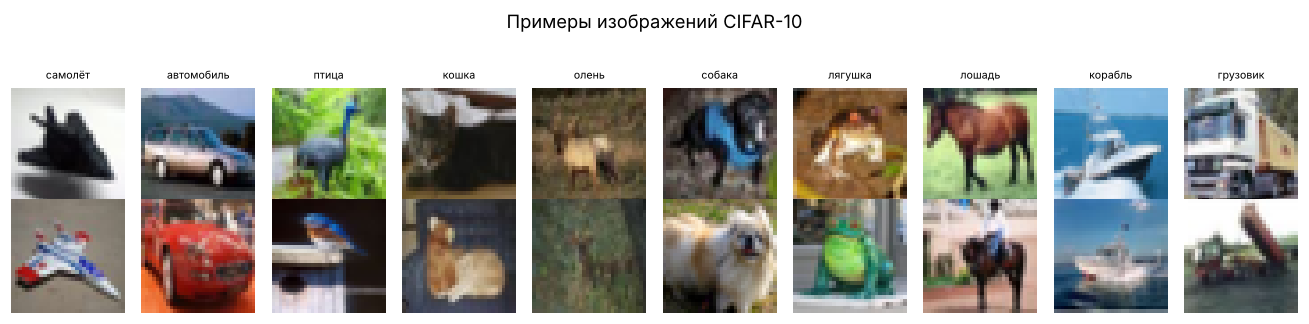

In [4]:
fig, axes = plt.subplots(2, 10, figsize=(12, 2.8))
Xr, yr = RAW['CIFAR-10'][0], RAW['CIFAR-10'][1]
for c in range(10):
    for row in range(2):
        j = np.flatnonzero(yr == c)[row]
        # imshow ждёт порядок осей (высота, ширина, канал), transpose переставляет оси
        axes[row, c].imshow(Xr[j].transpose(1, 2, 0))
        axes[row, c].axis('off')
    axes[0, c].set_title(CIFAR_CLASSES[c], fontsize=7)
fig.suptitle('Примеры изображений CIFAR-10', y=1.04)
plt.tight_layout()
plt.show()

## 3. Блоки и сети

In [5]:
def norm_layer(c, bn):
    """Батч-нормализация или пустышка, если нормализация выключена."""
    return nn.BatchNorm2d(c) if bn else nn.Identity()


class Block(nn.Module):
    """kind: plain - без соединения напрямую; residual - с соединением;
    bottleneck - свёртки 1x1 вокруг k x k, с соединением."""

    def __init__(self, c, kind='plain', ks=3, bn=True, dropout=0.0):
        super().__init__()
        pad = ks // 2
        if kind == 'bottleneck':
            mid = max(4, c // 4)  # внутри блока число каналов сжимается вчетверо
            layers = [nn.Conv2d(c, mid, 1), norm_layer(mid, bn), nn.ReLU(),
                      nn.Conv2d(mid, mid, ks, 1, pad), norm_layer(mid, bn), nn.ReLU(),
                      nn.Conv2d(mid, c, 1)]
        else:
            layers = [nn.Conv2d(c, c, ks, 1, pad), norm_layer(c, bn), nn.ReLU(),
                      nn.Conv2d(c, c, ks, 1, pad)]
        if dropout > 0:
            layers.append(nn.Dropout2d(dropout))
        layers.append(norm_layer(c, bn))  # нормализация стоит последней, до сложения
        self.body = nn.Sequential(*layers)
        self.kind = kind
        self.act = nn.ReLU()

    def forward(self, x):
        out = self.body(x)
        if self.kind in ('residual', 'bottleneck'):
            out = out + x  # соединение напрямую
        return self.act(out)


# варианты уменьшения карты вдвое: (kernel, stride) свёртки и пуллинга, 0 - без пуллинга
DOWN = {1: dict(conv_k=3, conv_s=1, pool_k=2, pool_s=2),
        2: dict(conv_k=3, conv_s=1, pool_k=3, pool_s=2),
        3: dict(conv_k=3, conv_s=2, pool_k=0, pool_s=0),
        4: dict(conv_k=5, conv_s=1, pool_k=2, pool_s=2)}


def downsample(c_in, c_out, bn, conv_k, conv_s, pool_k, pool_s):
    """Свёртка, нормализация, ReLU и пуллинг; карта признаков уменьшается вдвое."""
    layers = [nn.Conv2d(c_in, c_out, conv_k, conv_s, conv_k // 2), norm_layer(c_out, bn), nn.ReLU()]
    if pool_k:
        # дополнение 1 нужно только окну 3, чтобы из 32 получилось 16
        layers.append(nn.MaxPool2d(pool_k, pool_s, pool_k // 2 if pool_k % 2 else 0))
    return nn.Sequential(*layers)


class Net(nn.Module):
    """Входной слой, блоки при C каналах, переход с удвоением каналов, блоки при 2C,
    усреднение по карте признаков и многослойный перцептрон."""

    def __init__(self, kind='residual', n_blocks=4, channels=16, ks=3, bn=True,
                 dropout=0.0, head=(), down=1, in_ch=3):
        super().__init__()
        n1 = (n_blocks + 1) // 2  # блоки делятся между двумя стадиями поровну
        n2 = n_blocks - n1
        self.stem = downsample(in_ch, channels, bn, **DOWN[down])  # ** раскрывает словарь в аргументы
        # n1 блоков подряд; * раскрывает список блоков в аргументы Sequential
        self.stage1 = nn.Sequential(*[Block(channels, kind, ks, bn, dropout) for _ in range(n1)])
        self.transition = downsample(channels, 2 * channels, bn, **DOWN[down])
        self.stage2 = nn.Sequential(*[Block(2 * channels, kind, ks, bn, dropout) for _ in range(n2)])
        self.pool = nn.AdaptiveAvgPool2d(1)  # усреднение по всей карте признаков
        dims = [2 * channels] + list(head)
        layers = []
        for a, b in zip(dims[:-1], dims[1:]):
            layers += [nn.Linear(a, b), nn.ReLU()]
        layers.append(nn.Linear(dims[-1], 10))
        self.head = nn.Sequential(*layers)

    def forward(self, x):
        z = self.stage2(self.transition(self.stage1(self.stem(x))))
        return self.head(self.pool(z).flatten(1))


class ConvNet(nn.Module):
    """Сеть из лабораторной 5: блоки Conv-ReLU-MaxPool, у второго блока вдвое больше каналов."""

    def __init__(self, in_ch=3, size=32, n_blocks=2, ks=5, pool_k=3, pool_s=2, channels=8):
        super().__init__()
        layers, c_in = [], in_ch
        for i in range(n_blocks):
            c_out = channels * (i + 1)
            layers += [nn.Conv2d(c_in, c_out, ks, 1, ks // 2), nn.ReLU(), nn.MaxPool2d(pool_k, pool_s)]
            size = (size - pool_k) // pool_s + 1  # формула размера выхода пуллинга
            c_in = c_out
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Linear(c_in * size * size, 10)

    def forward(self, x):
        # flatten(1) вытягивает карту признаков в вектор, сохраняя ось объектов
        return self.classifier(self.features(x).flatten(1))

In [6]:
def evaluate(model, X, y, batch=500):
    """Доля верных ответов, считается батчами."""
    model.eval()  # батч-нормализация и дроп-аут переходят в режим применения
    correct = 0
    with torch.no_grad():  # при оценке градиенты не нужны
        for s in range(0, len(X), batch):
            correct += (model(X[s:s + batch]).argmax(1) == y[s:s + batch]).sum().item()
    return correct / len(X)


def run(model, Xtr, ytr, Xval, yval, lr, epochs, batch=64, seed=0, Xtest=None, ytest=None,
        keep_best=False):
    """Обучение SGD с моментом. После каждой эпохи accuracy на 1000 обучающих
    изображениях, на Xval и, если задана, на Xtest. При keep_best в конце
    в модель возвращаются веса с эпохи с лучшей accuracy на Xval."""
    torch.manual_seed(seed)
    best_state = None
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    lossf = nn.CrossEntropyLoss()
    hist = {'train': [], 'val': [], 'test': []}
    for _ in range(epochs):
        model.train()  # режим обучения: статистики батча и случайное обнуление
        perm = torch.randperm(len(Xtr), device=Xtr.device)  # новый порядок объектов
        for s in range(0, len(Xtr), batch):
            b = perm[s:s + batch]
            opt.zero_grad()  # обнуление градиентов прошлого шага
            lossf(model(Xtr[b]), ytr[b]).backward()  # градиенты функции потерь по весам
            opt.step()  # шаг оптимизатора
        hist['train'].append(evaluate(model, Xtr[:1000], ytr[:1000]))
        hist['val'].append(evaluate(model, Xval, yval))
        if Xtest is not None:
            hist['test'].append(evaluate(model, Xtest, ytest))
        if keep_best and hist['val'][-1] == max(hist['val']):
            # копия всех весов и статистик батч-нормализации на этой эпохе
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
    if keep_best:
        model.load_state_dict(best_state)
    return {k: np.array(v) for k, v in hist.items()}


def n_params(m):
    return sum(p.numel() for p in m.parameters())


EPOCHS = 10
BASE = dict(kind='residual', n_blocks=4, channels=16, ks=3, bn=True, dropout=0.0,
            head=(), down=1)


def experiment(stage, lr=0.05, **changes):
    """Обучение сети BASE с изменёнными параметрами на подвыборке CIFAR-10."""
    cfg = {**BASE, **changes}  # параметры BASE, часть из них заменена
    torch.manual_seed(20260905)
    model = Net(**cfg).to(DEVICE)  # веса на видеокарту
    h = run(model, Xc, yc, Xcv, ycv, lr=lr, epochs=EPOCHS)
    best = h['val'].argmax()
    return dict(stage=stage, **cfg, lr=lr, train_acc=float(h['train'][best]),
                val_acc=float(h['val'][best]), best_epoch=int(best) + 1,
                params=n_params(model), curve=list(np.round(h['val'], 4)))


demo = Net()
print(demo)
print(f'\nчисло параметров: {n_params(demo):,}')

Net(
  (stem): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (stage1): Sequential(
    (0): Block(
      (body): Sequential(
        (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU()
        (3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
      (act): ReLU()
    )
    (1): Block(
      (body): Sequential(
        (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_runn

## 4. Тип блока и глубина

In [7]:
rows = [experiment('глубина', kind=kind, n_blocks=nb)
        for kind, nb in itertools.product(['plain', 'residual', 'bottleneck'], [2, 4, 8])]
depth = pd.DataFrame(rows)
print(depth.pivot_table(index='n_blocks', columns='kind',
                        values=['train_acc', 'val_acc']).round(4).to_string())

          train_acc                    val_acc                 
kind     bottleneck  plain residual bottleneck   plain residual
n_blocks                                                       
2             0.522  0.616    0.522      0.505  0.5655   0.5100
4             0.581  0.515    0.571      0.547  0.4805   0.5345
8             0.561  0.450    0.522      0.529  0.4220   0.5055


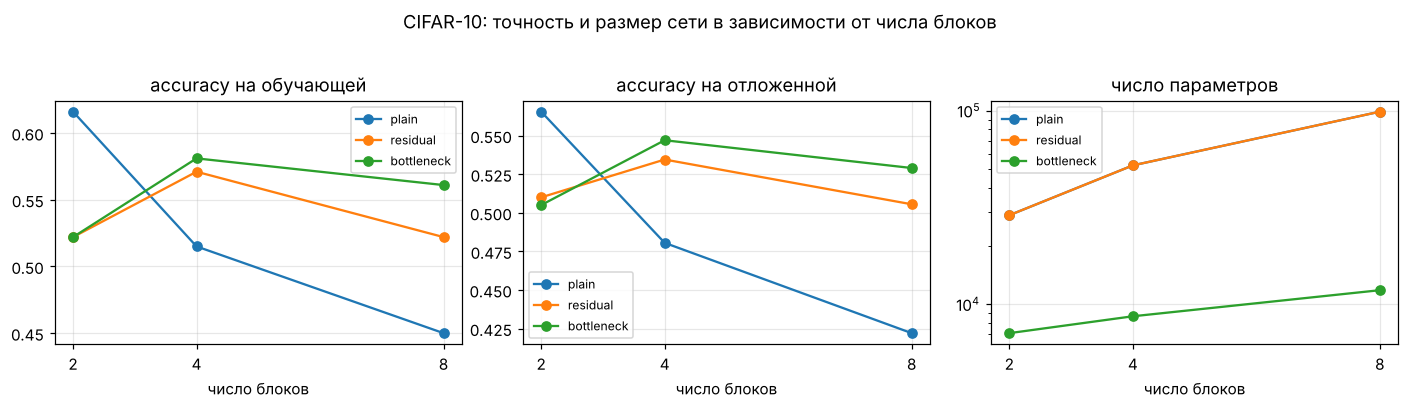

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for kind in ['plain', 'residual', 'bottleneck']:
    s = depth[depth.kind == kind].sort_values('n_blocks')
    axes[0].plot(s.n_blocks, s.train_acc, marker='o', label=kind)
    axes[1].plot(s.n_blocks, s.val_acc, marker='o', label=kind)
    axes[2].plot(s.n_blocks, s.params, marker='o', label=kind)
axes[0].set_title('accuracy на обучающей'); axes[1].set_title('accuracy на отложенной')
axes[2].set_title('число параметров'); axes[2].set_yscale('log')
for ax in axes:
    ax.set_xlabel('число блоков'); ax.set_xticks([2, 4, 8]); ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.suptitle('CIFAR-10: точность и размер сети в зависимости от числа блоков', y=1.02)
plt.tight_layout()
plt.show()

## 5. Батч-нормализация и дроп-аут

In [9]:
# выбор только среди блоков с соединением напрямую
best = depth[depth.kind != 'plain'].sort_values('val_acc', ascending=False).iloc[0]
BASE.update(kind=best['kind'], n_blocks=int(best['n_blocks']))
print(f'выбраны: блок {BASE["kind"]}, блоков {BASE["n_blocks"]}, accuracy {best["val_acc"]:.4f}')

rows = [experiment('bn и dropout', bn=bn, dropout=dp)
        for bn, dp in itertools.product([True, False], [0.0, 0.2, 0.5])]
regu = pd.DataFrame(rows)
regu['разрыв'] = regu.train_acc - regu.val_acc
print(regu[['bn', 'dropout', 'train_acc', 'val_acc', 'разрыв']].round(4).to_string(index=False))

выбраны: блок bottleneck, блоков 4, accuracy 0.5470


   bn  dropout  train_acc  val_acc  разрыв
 True      0.0      0.581   0.5470  0.0340
 True      0.2      0.432   0.4465 -0.0145
 True      0.5      0.460   0.4515  0.0085
False      0.0      0.424   0.4085  0.0155
False      0.2      0.407   0.4215 -0.0145
False      0.5      0.390   0.4010 -0.0110


## 6. Каналы и коэффициент обучения

In [10]:
best = regu.sort_values('val_acc', ascending=False).iloc[0]
BASE.update(bn=bool(best['bn']), dropout=float(best['dropout']))
print(f'выбраны: batchnorm {BASE["bn"]}, dropout {BASE["dropout"]}')

rows = [experiment('каналы и lr', lr=lr, channels=ch)
        for ch, lr in itertools.product([16, 32], [0.01, 0.05, 0.1])]
chan = pd.DataFrame(rows)
print(chan.pivot_table(index='channels', columns='lr', values='val_acc').round(4).to_string())

выбраны: batchnorm True, dropout 0.0


lr          0.01    0.05    0.10
channels                        
16        0.4745  0.5470  0.4845
32        0.5280  0.5635  0.5070


## 7. Параметры Conv2d и MaxPool2d, размер ядра в блоках

In [11]:
best = chan.sort_values('val_acc', ascending=False).iloc[0]
BASE.update(channels=int(best['channels']))
LR = float(best['lr'])
print(f'выбраны: каналов {BASE["channels"]}, lr {LR}')

rows = [experiment('уменьшение карты', lr=LR, down=d) for d in DOWN]
best_down = max(rows, key=lambda r: r['val_acc'])['down']
rows += [experiment('ядро в блоках', lr=LR, down=best_down, ks=5)]
conv = pd.DataFrame(rows)
conv['Conv2d'] = [f"{DOWN[d]['conv_k']}/{DOWN[d]['conv_s']}/{DOWN[d]['conv_k'] // 2}" for d in conv.down]
conv['MaxPool2d'] = [f"{DOWN[d]['pool_k']}/{DOWN[d]['pool_s']}/{DOWN[d]['pool_k'] // 2 if DOWN[d]['pool_k'] % 2 else 0}"
                     if DOWN[d]['pool_k'] else 'нет' for d in conv.down]
print(conv[['down', 'Conv2d', 'MaxPool2d', 'ks', 'train_acc', 'val_acc', 'params']]
      .round(4).to_string(index=False))

выбраны: каналов 32, lr 0.05


 down Conv2d MaxPool2d  ks  train_acc  val_acc  params
    1  3/1/1     2/2/0   3      0.618   0.5635   31978
    2  3/1/1     3/2/1   3      0.594   0.5245   31978
    3  3/2/1       нет   3      0.552   0.4950   31978
    4  5/1/2     2/2/0   3      0.567   0.5135   66282
    1  3/1/1     2/2/0   5      0.634   0.5515   42218


## 8. Выходной перцептрон

In [12]:
best = conv.sort_values('val_acc', ascending=False).iloc[0]
BASE.update(down=int(best['down']), ks=int(best['ks']))
print(f'выбраны: вариант уменьшения карты {BASE["down"]}, ядро в блоках {BASE["ks"]}')

HEADS = [(), (64,), (128,), (128, 64)]
heads = pd.DataFrame([experiment('выходной перцептрон', lr=LR, head=h) for h in HEADS])
heads['head'] = heads['head'].astype(str)
print(heads[['head', 'train_acc', 'val_acc', 'params']].round(4).to_string(index=False))
BASE.update(head=HEADS[int(heads.val_acc.values.argmax())])

allres = pd.concat([depth, regu.drop(columns='разрыв'), chan, conv.drop(columns=['Conv2d', 'MaxPool2d']), heads],
                   ignore_index=True)
allres['head'] = allres['head'].astype(str)
allres.drop(columns='curve').to_csv('results.csv', index=False)
print('\nитоговая конфигурация:', BASE, f'lr {LR}')

выбраны: вариант уменьшения карты 1, ядро в блоках 3


     head  train_acc  val_acc  params
       ()      0.618   0.5635   31978
    (64,)      0.490   0.4590   36138
   (128,)      0.491   0.4980   40938
(128, 64)      0.441   0.4225   48554

итоговая конфигурация: {'kind': 'bottleneck', 'n_blocks': 4, 'channels': 32, 'ks': 3, 'bn': True, 'dropout': 0.0, 'head': (), 'down': 1} lr 0.05


## 9. Число эпох

Сеть с выбранными параметрами обучается 20 эпох на 15000 изображениях. Число эпох
выбирается по наибольшей accuracy на отложенных 2000 изображениях, и в модели
остаются веса с этой эпохи; точность на тестовой выборке приводится для неё же.

лучшая эпоха по отложенной выборке: 18, accuracy на отложенной 0.6630, на тестовой (10000) 0.6850
число параметров: 31,978


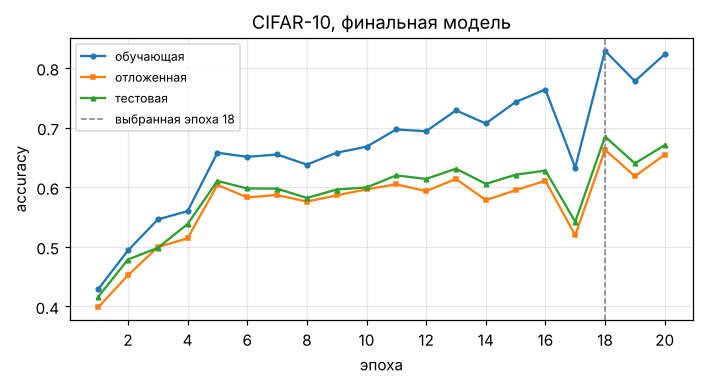

In [13]:
(Xb, yb), (Xbv, ybv), _ = split('CIFAR-10', 15000, 2000, np.random.default_rng(1))
torch.manual_seed(20260905)
final = Net(**BASE).to(DEVICE)
hist = run(final, Xb, yb, Xbv, ybv, lr=LR, epochs=20, Xtest=Xct, ytest=yct, keep_best=True)
best_ep = int(hist['val'].argmax()) + 1
print(f'лучшая эпоха по отложенной выборке: {best_ep}, accuracy на отложенной '
      f'{hist["val"][best_ep - 1]:.4f}, на тестовой (10000) {hist["test"][best_ep - 1]:.4f}')
print(f'число параметров: {n_params(final):,}')

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ep = range(1, 21)
ax.plot(ep, hist['train'], marker='o', ms=3, label='обучающая')
ax.plot(ep, hist['val'], marker='s', ms=3, label='отложенная')
ax.plot(ep, hist['test'], marker='^', ms=3, label='тестовая')
ax.axvline(best_ep, color='gray', ls='--', lw=1, label=f'выбранная эпоха {best_ep}')
ax.set_xlabel('эпоха'); ax.set_ylabel('accuracy'); ax.set_xticks(range(2, 21, 2))
ax.set_title('CIFAR-10, финальная модель'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

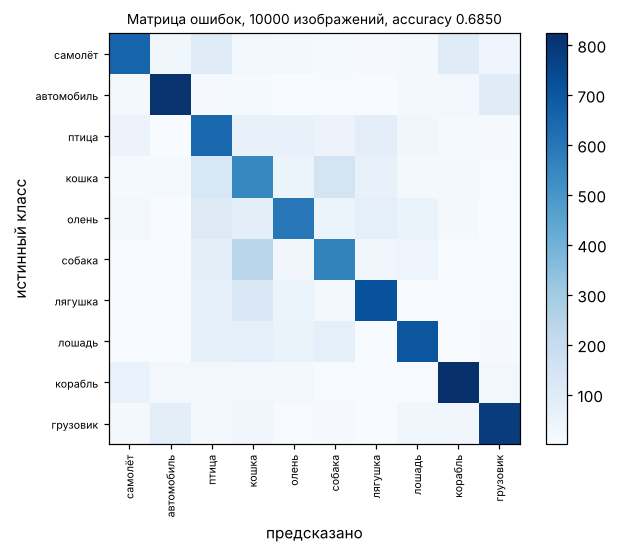

              precision    recall  f1-score   support

     самолёт      0.779     0.654     0.711      1000
  автомобиль      0.833     0.813     0.823      1000
       птица      0.516     0.644     0.573      1000
       кошка      0.454     0.549     0.497      1000
       олень      0.683     0.596     0.636      1000
      собака      0.600     0.563     0.581      1000
     лягушка      0.724     0.719     0.722      1000
      лошадь      0.764     0.703     0.732      1000
     корабль      0.802     0.824     0.813      1000
    грузовик      0.805     0.785     0.795      1000

    accuracy                          0.685     10000
   macro avg      0.696     0.685     0.688     10000
weighted avg      0.696     0.685     0.688     10000



In [14]:
# в final уже лежат веса с выбранной эпохи
final.eval()
with torch.no_grad():  # без подсчёта градиентов, батчами по 500
    pred = torch.cat([final(Xct[s:s + 500]).argmax(1) for s in range(0, len(Xct), 500)])
pred = pred.cpu().numpy()  # .cpu() забирает тензор с видеокарты
y_true = yct.cpu().numpy()

cm = confusion_matrix(y_true, pred)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xticklabels(CIFAR_CLASSES, rotation=90, fontsize=7)
ax.set_yticklabels(CIFAR_CLASSES, fontsize=7)
ax.set_xlabel('предсказано'); ax.set_ylabel('истинный класс')
ax.set_title(f'Матрица ошибок, 10000 изображений, accuracy {np.mean(pred == y_true):.4f}', fontsize=9)
plt.colorbar(im)
plt.tight_layout()
plt.show()

print(classification_report(y_true, pred, target_names=CIFAR_CLASSES, digits=3, zero_division=0))

## 10. Сравнение с неостаточными сетями на трёх выборках

На каждой выборке четыре сети обучаются на 5000 изображениях 10 эпох и
проверяются на тестовой выборке из 10000 изображений: сеть из лабораторной 5 и
сети с выбранными параметрами из блоков трёх видов. Сети из блоков plain и
residual имеют одинаковое число параметров и отличаются только соединениями
напрямую. Как и при переборе, в сети остаются веса с эпохи с наибольшей accuracy
на отложенных 2000 изображениях.

In [15]:
rows = []
for ds in ['CIFAR-10', 'FashionMNIST', 'MNIST']:
    (Xa, ya), (Xav, yav), (Xat, yat) = split(ds, 5000, 2000, np.random.default_rng(20260905))
    in_ch, size = Xa.shape[1], Xa.shape[2]
    for net_name in ['лаб. 5 (Conv-ReLU-MaxPool)', 'plain', 'residual', 'bottleneck']:
        torch.manual_seed(20260905)
        if net_name.startswith('лаб. 5'):
            model, lr = ConvNet(in_ch=in_ch, size=size), 0.01
        else:
            model, lr = Net(**{**BASE, 'kind': net_name}, in_ch=in_ch), LR
        model = model.to(DEVICE)
        h = run(model, Xa, ya, Xav, yav, lr=lr, epochs=EPOCHS, keep_best=True)
        best = int(h['val'].argmax())
        rows.append(dict(dataset=ds, сеть=net_name, best_epoch=best + 1,
                         train_acc=float(h['train'][best]), val_acc=float(h['val'][best]),
                         test_acc=evaluate(model, Xat, yat), params=n_params(model)))
cmp = pd.DataFrame(rows)
cmp.to_csv('results_comparison.csv', index=False)
print(cmp.round(4).to_string(index=False))

     dataset                       сеть  best_epoch  train_acc  val_acc  test_acc  params
    CIFAR-10 лаб. 5 (Conv-ReLU-MaxPool)           8      0.637   0.5465    0.5195   11674
    CIFAR-10                      plain           9      0.563   0.5295    0.5115  205706
    CIFAR-10                   residual           8      0.551   0.5160    0.5118  205706
    CIFAR-10                 bottleneck          10      0.618   0.5635    0.5455   31978
FashionMNIST лаб. 5 (Conv-ReLU-MaxPool)           8      0.901   0.8610    0.8539    9194
FashionMNIST                      plain          10      0.904   0.8660    0.8619  205130
FashionMNIST                   residual           5      0.852   0.8420    0.8398  205130
FashionMNIST                 bottleneck           9      0.898   0.8520    0.8458   31402
       MNIST лаб. 5 (Conv-ReLU-MaxPool)          10      1.000   0.9785    0.9790    9194
       MNIST                      plain           9      0.994   0.9840    0.9828  205130
       MNI

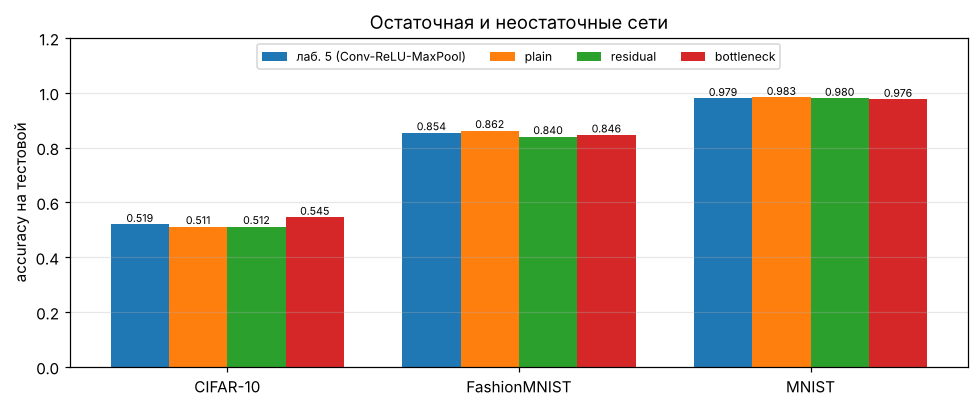

In [16]:
fig, ax = plt.subplots(figsize=(9, 3.8))
datasets = ['CIFAR-10', 'FashionMNIST', 'MNIST']
names = list(cmp['сеть'].unique())
xs = np.arange(len(datasets))
w = 0.2
for i, name in enumerate(names):
    s = cmp[cmp['сеть'] == name].set_index('dataset').loc[datasets]
    bars = ax.bar(xs + (i - 1.5) * w, s.test_acc.values, w, label=name)
    ax.bar_label(bars, fmt='%.3f', fontsize=7)  # значение над каждым столбцом
ax.set_xticks(xs); ax.set_xticklabels(datasets)
ax.set_ylim(0, 1.2); ax.set_ylabel('accuracy на тестовой')
ax.set_title('Остаточная и неостаточные сети'); ax.legend(fontsize=8, loc='upper center', ncol=4)
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()